# Digital pathology preprocessing demo
Inspect H&E lung WSIs, compare tissue/artefact masks, export the full eligible CLAM coordinate grid and review sampled QC on thumbnails. The main example is TCGA-LUAD case **TCGA-55-6972**; a second WSI shows severe pen marks.

**Preprocessing is a user choice and a scientific decision.** The selected lung profile disables explicit hole filling and smooths binary mask edges; suitability depends on specimen, stain and research question. These are demonstration settings, not a validated diagnostic pipeline. Tissue masks do not identify tumour, and patient diagnoses do not label every tile.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
from copy import deepcopy
from omegaconf import OmegaConf
from hydra import compose, initialize_config_dir
import hashlib
import json
import platform
import time
import sys
import subprocess
import uuid

import cv2
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import openslide
import pandas as pd
from PIL import Image
from IPython import get_ipython
from IPython.display import display, HTML
from matplotlib_inline.backend_inline import set_matplotlib_formats

get_ipython().run_line_magic('matplotlib', 'inline')
set_matplotlib_formats('png')  # Embed portable PNG figures without retina-size duplication.

PROJECT = None  # Optional: set Path(...) to the checkout when launching elsewhere.
if PROJECT is None:
    PROJECT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / 'pyproject.toml').is_file()
                    and (p / 'src/wsi_preprocessing/preprocess.py').is_file()), None)
    if PROJECT is None:
        raise FileNotFoundError('Open this notebook from the project, or set PROJECT to its checkout directory.')
PROJECT = Path(PROJECT).expanduser().resolve(strict=True)
assert (PROJECT / 'src/wsi_preprocessing/preprocess.py').is_file(), 'PROJECT must point to this project checkout.'
sys.path.insert(0, str(PROJECT))
# Use the repository downloader only for missing canonical demo inputs.
subprocess.run([sys.executable, str(PROJECT / 'scripts/prepare_demo_inputs.py'),
                '--demo', 'preprocessing'], check=True, cwd=PROJECT)
from src.utils.files import source_hashes
from src.wsi_preprocessing.inspection import read_thumbnail, read_slide_metadata
from src.imaging_utils.arrays import save_png, mean_background_color, tissue_hole_preview
from src.wsi_preprocessing.pipeline import preprocess_masks
from src.imaging_utils.filters import resolve_pen_thresholds
from src.wsi_preprocessing.tiling import calibrated_patch_size, read_tile, open_clam_slide, clam_contours, contour_tile_mask, mask_bounds, CLAM_COMMIT
from src.wsi_preprocessing.export import export_slide
from src.imaging_utils.quality import tile_quality
from src.imaging_utils.normalization import prepare_stain_image, compare_stain_normalization
SLIDE_ID = '20c9afac-0d0c-4fcf-b3bf-a2beba3dd76b'
SLIDE_PATH = PROJECT / 'data/tcga/TCGA-LUAD' / f'{SLIDE_ID}.svs'
OUTPUT_ROOT = PROJECT / 'outputs' / 'preprocessing_demo'
THUMBNAIL_EDGE = 1024
MAX_THUMBNAIL_READ_PIXELS = 4_000_000
PROFILE = 'lung'
CONFIG_PATH = PROJECT / 'configs' / f'{PROFILE}.yaml'
# Compose inheritance and config groups once; raw loading lung.yaml would miss its defaults.
with initialize_config_dir(version_base=None, config_dir=str(PROJECT / 'configs')):
    CONFIG = compose(config_name=PROFILE)
    GENERIC_CONFIG = compose(config_name='preprocess')  # Comparison only, not used for tiling.
EXPORT = deepcopy(CONFIG.export)
# Keep all eligible coordinates; source-pixel reads happen only in the QC section.
EXPORT.coordinate_limit = None
EXPORT.pixel_slide_id = None
EXPORT.max_patches = [0]
# Change tiling choices on EXPORT before deriving these display/read values.
TARGET_MPP = float(EXPORT.target_mpp)
TILE_PIXELS = int(EXPORT.patch_sizes[0])
MIN_TISSUE_FRACTION = float(EXPORT.min_tissue_fraction)
CLAM_CONTOUR_FN = str(EXPORT.contour_fn)
MAX_CONTOURS = int(EXPORT.max_contours)
MAX_GRID_POSITIONS = int(EXPORT.max_candidates)  # Safety budget: fail, never silently truncate.
N_QC_PATCHES = 12                 # Visual examples only; not a coordinate-export limit.
MAX_TILE_READ_PIXELS = 1_000_000
MAX_TILE_SECONDS = 120           # checked between reads; each read is pixel-bounded
stain_provenance = None          # Export remains valid if optional normalisation is skipped.

assert 0 < TARGET_MPP and 64 <= TILE_PIXELS <= 512
assert 128 <= THUMBNAIL_EDGE <= 2048
assert 0 <= MIN_TISSUE_FRACTION <= 1
assert list(EXPORT.patch_sizes) == [256] and EXPORT.tiling_method == 'clam_four_pt'
assert 4 <= N_QC_PATCHES <= 36
assert SLIDE_PATH.is_file(), f'Local slide missing: {SLIDE_PATH}'
cv2.setNumThreads(1)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.titlesize': 12})
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8]
OUT = OUTPUT_ROOT / run_id
OUT.mkdir(parents=True, exist_ok=False)
started = time.monotonic()
print(f'Python: {sys.executable}')
print(f'Profile: {PROFILE} ({CONFIG_PATH})')
print(f'Outputs: {OUT}')

Matplotlib is building the font cache; this may take a moment.


{
  "demo": "preprocessing",
  "project": "/Users/irina/Projects/digital-pathology-demo",
  "commands_run": [],
  "missing": [],
  "tcga": {
    "slides": 2,
    "bytes": 461344700,
    "integrity_check": "GDC size and MD5",
    "missing_before": []
  },
  "status": "ready"
}
Python: /Users/irina/Projects/digital-pathology-demo/.venv/bin/python
Profile: lung (/Users/irina/Projects/digital-pathology-demo/configs/lung.yaml)
Outputs: /Users/irina/Projects/digital-pathology-demo/outputs/pipeline-audit-20261103/normalisation-patch-mask-publish-validation/attempt-2/runs/20261103T212800Z_db611c8e


### Preprocessing choices
These settings come from Hydra's composed **`lung` profile**, including inherited config groups. This is the user's scientific choice for sparse lung tissue, not a validated anatomy detector. The controls below expose the tradeoff between tissue loss and artefact retention. Sizes and areas below are in thumbnail pixels; changing `THUMBNAIL_EDGE` changes their physical meaning.

**Air spaces and thin septa are anatomy; pen, debris and tissue tears are different phenomena.** A hole in a binary mask does not diagnose an artefact, and a small connected component is not necessarily debris. Thresholding can already lose pale septa; morphological operations can further erase thin structures or seal genuine air spaces.

| Control | Effect in the lung profile |
| --- | --- |
| `ARTIFACTS['pen_colors']` | Enabled pen colours; `[]` disables pen masking |
| `ARTIFACTS['pen_thresholds']` | Per-colour replacement rule lists; `None` uses CODAIT defaults |
| `MASKING['tia_threshold']` | `None` fits grayscale Otsu; a number overrides it (higher retains lighter pixels) |
| `MASKING['tia_enabled']` | Enable/disable the TIA preliminary gate |
| `MASKING['median_size']` | Saturation median window; 1 leaves values unsmoothed |
| `MASKING['use_otsu']`, `['saturation_threshold']` | Automatic CLAM saturation threshold, or fixed 0–255 threshold |
| `MASKING['closing_size']` | 0: do not bridge spaces at saturation thresholding |
| `MASKING['max_hole_area']` | 0: disable the dedicated hole-filling step; binary morphology can still change holes |
| `MASKING['smoothing_kernel_size']` | 3: opening then closing of the binary mask with a 3-pixel elliptical kernel; 0 disables |
| `ARTIFACTS['min_tissue_area']` | 16: minimum component area; still a heuristic |
| `EXPORT.min_tissue_fraction` | 0.10: allow sparse tissue footprints; change in the setup cell |
| `EXPORT.exclude_hole_centers` | `False`: retain mask holes but do not veto a patch solely because its centre falls in one |

At **10% retained-mask coverage**, up to **90% of its thumbnail-mask area can be unretained**, potentially including background or artefacts. This is not a bound on tissue or artefact content in the full-resolution patch. This is a permissive location rule, not an artefact-free guarantee; thumbnail and patch QC remain necessary.

**Custom pen rules:** each `[r, g, b]` triple is one rule. Red means `R>r & G<g & B<b`; green means `R<r & G>g & B>b`; blue means `R<r & G<g & B>b`. Values are integers 0–255. Rules within a colour are OR'ed: tightening one rule may have no effect if another still matches. Supplying a colour replaces its entire list; omitted colours keep their defaults. These are colour heuristics and can remove real stained tissue.

**Smoothing is an independent scientific choice.** Opening can remove thin tissue; closing can bridge gaps and change holes even when `max_hole_area=0`. The configured smoothing is applied before final cleanup and tiling. It changes only binary mask membership: no RGB interpolation, neighbour-colour averaging, inpainting or soft probability mask.


In [2]:
MASKING = OmegaConf.to_container(CONFIG.masking, resolve=True)
ARTIFACTS = OmegaConf.to_container(CONFIG.artifacts, resolve=True)

# Follow the composed lung profile; put only deliberate notebook experiments here.
MASKING_OVERRIDES = {}
ARTIFACT_OVERRIDES = {}
MASKING.update(MASKING_OVERRIDES)
ARTIFACTS.update(ARTIFACT_OVERRIDES)

# Example: replace ALL blue rules with one stricter blue rule:
# ARTIFACTS['pen_thresholds'] = {'blue': [[60, 100, 210]]}
# Example: edit one original rule and preserve the other blue rules:
# custom = {color: [list(rule) for rule in rules]
#           for color, rules in resolve_pen_thresholds().items()}
# custom['blue'][0] = [60, 100, 210]
# ARTIFACTS['pen_thresholds'] = custom
# Example: use a fixed CLAM threshold instead of saturation Otsu:
# MASKING.update(use_otsu=False, saturation_threshold=30)
print(OmegaConf.to_yaml(OmegaConf.create({'masking': MASKING, 'artifacts': ARTIFACTS})))


masking:
  method: codait_tia_clam
  tia_enabled: true
  tia_threshold: null
  median_size: 1
  use_otsu: true
  saturation_threshold: 20
  closing_size: 0
  max_hole_area: 0
  smoothing_kernel_size: 3
artifacts:
  pen_colors:
  - red
  - green
  - blue
  pen_thresholds: null
  remove_dark: true
  dark_threshold: 30
  remove_gray: false
  gray_tolerance: 15
  min_tissue_area: 16
  warn_removed_fraction: 0.25



## Steps
### 1. Inspect the slide and its physical scale
A WSI is usually stored as an **image pyramid**. Level 0 has the most detail; higher-numbered levels are smaller. We read a small pyramid level for the overview and local regions for individual tiles.

**MPP** tells us how much tissue each pixel represents. At 0.5 µm/pixel, a 256-pixel tile covers **128 × 128 µm**. A “20×” label alone is less precise than physical calibration.

The local manifest records this public diagnostic slide and its expected checksum. Checking the checksum identifies the exact source without copying the WSI.

In [3]:
manifest_path = PROJECT / 'manifests/tcga_demo.csv'
manifest = pd.read_csv(manifest_path)
source = manifest.loc[manifest.file_id.eq(SLIDE_ID)]
assert len(source) == 1, 'Expected exactly one source record'
source = source.iloc[0].to_dict()
source_stat = SLIDE_PATH.stat()
with SLIDE_PATH.open('rb') as stream:
    source_md5 = hashlib.file_digest(stream, 'md5').hexdigest()
assert source_md5 == source['md5sum'], 'WSI differs from the local manifest'

slide_metadata = read_slide_metadata(SLIDE_PATH)
width, height = slide_metadata['dimensions']
levels = slide_metadata['level_dimensions']
downsamples = slide_metadata['level_downsamples']
mpp_x, mpp_y = slide_metadata['native_mpp_xy']
assert mpp_x is not None and mpp_y is not None, 'Recorded MPP is required; do not infer it from objective power.'
assert np.isfinite([mpp_x, mpp_y]).all() and min(mpp_x, mpp_y) > 0
(OUT / 'wsi_metadata.json').write_text(json.dumps(slide_metadata, indent=2))

summary = {key: slide_metadata[key] for key in
           ['filename', 'file_size_bytes', 'vendor', 'objective_power', 'native_mpp_xy',
            'dimensions', 'physical_size_mm', 'level_count', 'bounds_level0',
            'associated_images', 'icc_profile_present', 'icc_profile_description']}
display(pd.DataFrame({'field': list(summary), 'value': [str(v) for v in summary.values()]}))
display(pd.DataFrame({'level': range(len(levels)), 'width_px': [v[0] for v in levels],
                      'height_px': [v[1] for v in levels], 'downsample': downsamples,
                      'approx_mpp_x': np.asarray(downsamples) * mpp_x,
                      'approx_mpp_y': np.asarray(downsamples) * mpp_y}))
raw_properties = pd.DataFrame(sorted(slide_metadata['properties'].items()), columns=['OpenSlide property', 'value'])
display(HTML('<details><summary>Expand all raw scanner/OpenSlide properties</summary>'
             + raw_properties.to_html(index=False, escape=True) + '</details>'))
print(f"Verified source checksum; read {len(raw_properties)} properties without decoding slide pixels.")


,field,value
0,filename,20c9afac-0d0c-4fcf-b3bf-a2beba3dd76b.svs
1,file_size_bytes,59772831
2,vendor,aperio
3,objective_power,40.0
4,native_mpp_xy,"[0.252, 0.252]"
5,dimensions,"[26858, 32068]"
6,physical_size_mm,"[6.768216000000001, 8.081136]"
7,level_count,3
8,bounds_level0,"{'x': None, 'y': None, 'width': None, 'height'..."
9,associated_images,['thumbnail']


,level,width_px,height_px,downsample,approx_mpp_x,approx_mpp_y
0,0,26858,32068,1.000000,0.252000,0.252000
1,1,6714,8017,4.000149,1.008038,1.008038
2,2,1678,2004,16.003978,4.033002,4.033002


OpenSlide property,value
aperio.AppMag,40
aperio.DSR ID,aperio01
aperio.Date,10/23/11
aperio.DisplayColor,0
aperio.Exposure Scale,0.000001
aperio.Exposure Time,109
aperio.Filename,27373
aperio.Focus Offset,0.000000
aperio.ICC Profile,ScanScope v1
aperio.ImageID,27373


Verified source checksum; read 52 properties without decoding slide pixels.


### Now read the first slide image
Metadata came first: no WSI or associated-image pixels were decoded in the previous cell. Scanner properties can be missing or vendor-specific. Physical slide size includes background and is not specimen size. Associated-image **names** are listed, but label/macro images are not displayed.

We now read a bounded low-resolution pyramid level for the overview. The full gigapixel image stays on disk.

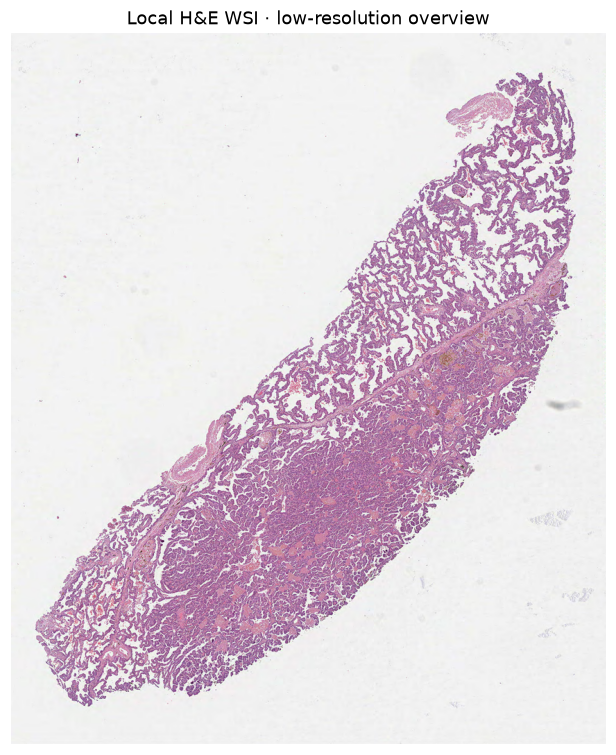

In [4]:
rgb, inspection = read_thumbnail(SLIDE_PATH, THUMBNAIL_EDGE,
                                 MAX_THUMBNAIL_READ_PIXELS, MAX_THUMBNAIL_READ_PIXELS)
thumbnail = Image.fromarray(rgb)
thumb_level = inspection['read_level']
thumb_h, thumb_w = rgb.shape[:2]
scale_x, scale_y = width / thumb_w, height / thumb_h
fig, ax = plt.subplots(figsize=(6, 7))
ax.imshow(rgb)
ax.set_title('Local H&E WSI · low-resolution overview')
ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / '01_overview.png')
plt.show()

**Look together:** identify coloured tissue and background; inspect high-resolution tiles later for folds, pen marks, bubbles and blur. A thumbnail cannot establish focus quality. No tumour regions are annotated here. Colours are decoded scanner RGB; ICC conversion is not applied.

### 2. Run the combined tissue/QC pipeline with the lung profile
The notebook and CLI now share `src.wsi_preprocessing.pipeline.preprocess_masks`:

1. **CODAIT colour rules** identify pen-like pixels, plus configured dark/grey pixels. Replace these with white in a working image, leaving source RGB intact.
2. **TIA Otsu** finds a grayscale threshold on that working image. Whiten pixels outside its preliminary tissue mask.
3. **CLAM-style masking** applies HSV saturation → median filter → fixed or Otsu saturation threshold → optional closing. This is a second, separate threshold in a different colour channel.
4. **Optional small-hole cleanup** fills enclosed background components up to the chosen area. The lung profile disables this step and threshold closing; the separate binary smoothing step can still alter spaces.
5. **Binary mask smoothing** applies opening followed by closing with a 3-pixel elliptical kernel. It softens the shape of binary mask edges without changing the original RGB or creating probability values. The smoothed candidate feeds final cleanup and tiling; 0 disables it.
6. **Final QC** reapplies CODAIT exclusions and removes small tissue components. Neither hole filling nor smoothing can retain CODAIT-excluded pixels after this cleanup.

Our hole policy uses **raster areas in thumbnail pixels**, not upstream CLAM's reference-patch-scaled contour areas or maximum-hole count. It is CLAM-style preprocessing, not numerical equivalence to CLAM. Filling holes can erase real lung air spaces: compare the intermediate masks before choosing parameters.

The stage comparison keeps this same slide in one row, with processing stages in columns.


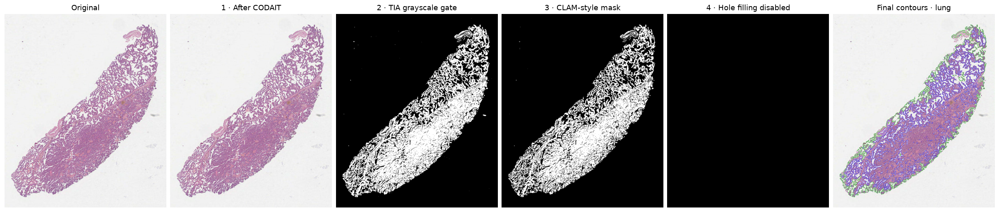

TIA grayscale threshold: 190/255; CLAM saturation threshold: 41/255
Filled 0 thumbnail pixels; final retained area 22.4% (not a tumour percentage).


In [5]:
rgb_before_preprocessing = rgb.copy()
rgb_before_preprocessing_sha256 = hashlib.sha256(rgb.tobytes()).hexdigest()
result = preprocess_masks(rgb, masking=MASKING, artifacts=ARTIFACTS)
assert np.array_equal(rgb, rgb_before_preprocessing), 'Preprocessing modified the original RGB.'
mask = result['clean']
assert mask.dtype == bool
otsu_threshold = result['metadata']['clam_saturation_threshold']
assert mask.any(), 'No tissue retained: inspect the intermediate masks and parameters.'
assert not np.any(mask & result['excluded'])
final_contours_preview, _ = tissue_hole_preview(rgb, mask)
views = [rgb, result['stages']['codait_filtered'], result['stages']['tia_otsu'],
         result['stages']['clam_mask'], result['stages']['filled_holes'], final_contours_preview]
titles = ['Original', '1 · After CODAIT', '2 · TIA grayscale gate',
          '3 · CLAM-style mask',
          '4 · Hole filling disabled' if MASKING['max_hole_area'] == 0 else '4 · Filled small holes',
          f'Final contours · {PROFILE}']
fig, axes = plt.subplots(1, 6, figsize=(22, 5), layout='constrained')
for ax, im, title in zip(axes.flat, views, titles):
    ax.imshow(im, cmap='gray' if im.ndim == 2 else None)
    ax.set_title(title)
    ax.axis('off')
fig.savefig(OUT / '02_tissue_mask.png')
plt.show()
tia_threshold = result['metadata']['tia_threshold']
tia_threshold_text = 'disabled' if tia_threshold is None else f'{tia_threshold:.0f}/255'
print(f"TIA grayscale threshold: {tia_threshold_text}; "
      f"CLAM saturation threshold: {otsu_threshold:.0f}/255")
print(f"Filled {result['metadata']['filled_hole_pixels']} thumbnail pixels; "
      f"final retained area {mask.mean():.1%} (not a tumour percentage).")


### Compare profile choices on the same thumbnail
The generic `preprocess` profile and active `lung` profile are shown in columns over the **same original RGB**, with green tissue and blue hole contours. Their settings differ in several steps, so this illustrates a profile choice rather than attributing every difference to one parameter. Neither is declared scientifically superior; inspect septa, spaces, lost tissue and retained artefacts. The comparison does **not** replace the active `mask` used for tiling.

A second figure shows the **configured binary-mask opening/closing actually used for tiling**. Before and after are both before final CODAIT/component cleanup, isolating that morphological step. Green tissue and blue hole contours are drawn over the same original RGB. Smoothing changes mask geometry only; it can erase thin septa or seal spaces, so inspect both views.


Original patch colours and textures remain available because smoothing touches only the binary mask; anatomical retention still depends on the resulting mask.


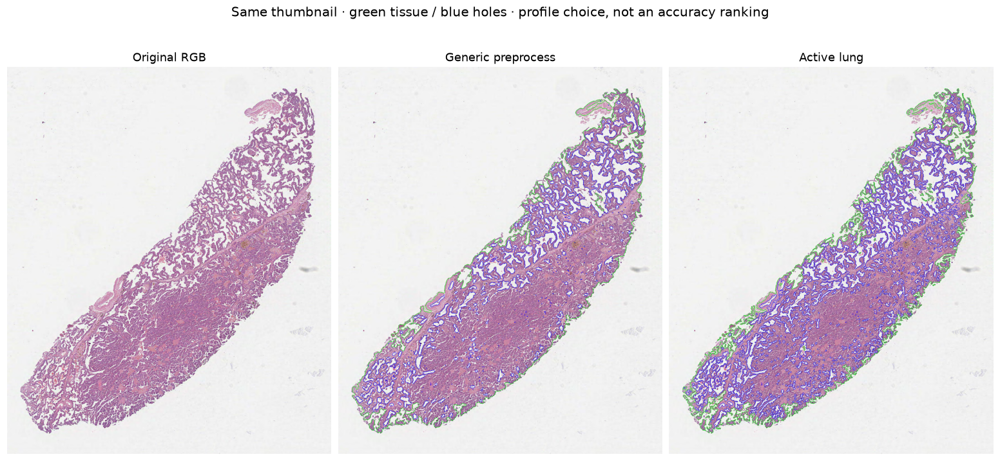

,profile,retained_area_pct,changed_pixels_vs_active
0,Generic preprocess,25.51,39126
1,Active lung,22.38,0


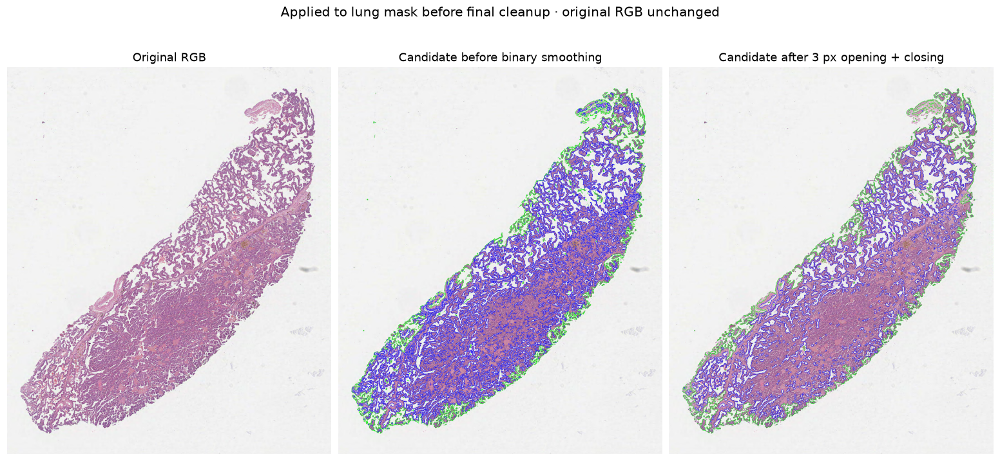

Binary smoothing added 16,102 and removed 10,679 candidate-mask pixels; inspect thin tissue and spaces before choosing the setting.


In [6]:
generic_masking = OmegaConf.to_container(GENERIC_CONFIG.masking, resolve=True)
generic_artifacts = OmegaConf.to_container(GENERIC_CONFIG.artifacts, resolve=True)
generic_result = preprocess_masks(rgb, masking=generic_masking, artifacts=generic_artifacts)
profile_variants = [('Generic preprocess', generic_result), (f'Active {PROFILE}', result)]
fig, axes = plt.subplots(1, 3, figsize=(14, 7), layout='constrained')
axes[0].imshow(rgb)
axes[0].set_title('Original RGB')
axes[0].axis('off')
profile_comparison = []
for ax, (name, variant) in zip(axes[1:], profile_variants, strict=True):
    preview, _ = tissue_hole_preview(rgb, variant['clean'])
    ax.imshow(preview)
    ax.set_title(name)
    ax.axis('off')
    profile_comparison.append({'profile': name, 'retained_area_pct': 100 * variant['clean'].mean(),
                       'changed_pixels_vs_active': int(np.count_nonzero(mask != variant['clean']))})
fig.suptitle('Same thumbnail · green tissue / blue holes · profile choice, not an accuracy ranking')
fig.savefig(OUT / '02b_parameter_comparison.png')
plt.show()
display(pd.DataFrame(profile_comparison).round(2))

smoothing_before = result['stages']['before_smoothing']
smoothing_after = result['stages']['smoothed_mask']
assert smoothing_before.dtype == smoothing_after.dtype == bool
assert np.array_equal(rgb, rgb_before_preprocessing)
before_smoothing_preview, _ = tissue_hole_preview(rgb, smoothing_before)
after_smoothing_preview, _ = tissue_hole_preview(rgb, smoothing_after)
mask_smoothing_provenance = {
    'kernel_size': MASKING['smoothing_kernel_size'], 'used_for_tiling': True,
    'domain': 'binary thumbnail mask only', 'original_rgb_modified': False,
    'input_stage': 'before_smoothing', 'output_stage': 'smoothed_mask',
    'before_final_cleanup': True,
    'added_pixels': int(np.count_nonzero(smoothing_after & ~smoothing_before)),
    'removed_pixels': int(np.count_nonzero(smoothing_before & ~smoothing_after)),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 7), layout='constrained')
for ax, image, title in zip(axes,
        (rgb, before_smoothing_preview, after_smoothing_preview),
        ('Original RGB', 'Candidate before binary smoothing',
         f"Candidate after {MASKING['smoothing_kernel_size']} px opening + closing"), strict=True):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle(f'Applied to {PROFILE} mask before final cleanup · original RGB unchanged')
fig.savefig(OUT / '02c_mask_smoothing.png')
plt.show()
print(f"Binary smoothing added {mask_smoothing_provenance['added_pixels']:,} and removed "
      f"{mask_smoothing_provenance['removed_pixels']:,} candidate-mask pixels; "
      'inspect thin tissue and spaces before choosing the setting.')


### Severe pen artefacts: TIA, native CLAM and the combined recipe
Compare three approaches on **one additional real WSI**, TCGA-LUSC case **TCGA-85-7698**, with prominent red, green and blue pen strokes. The setup step obtains missing inputs; this comparison reads the canonical source without copying it. The main slide, mask and tiling settings above remain unchanged.

- **TIA Otsu:** the unmodified RGB thumbnail, with no CODAIT or component cleanup.
- **Native CLAM:** the pinned upstream `segmentTissue` method, with explicit CLI-default settings: fixed saturation threshold 8, median 7, closing 4, tissue area 100 and hole area 16 in CLAM's reference-patch-scaled units, and at most 8 holes per contour; reference patch size 512. Its native pyramid level is selected nearest the requested downsample 64 and must fit the 16-million-pixel read budget.
- **Repo (lung):** the current composed lung `MASKING` and `ARTIFACTS` settings, including deliberate overrides above. The same scientific choice disables dedicated hole filling and applies binary mask smoothing before final cleanup; this does not diagnose which spaces are anatomical. Original RGB stays unchanged.

TIA and the combination receive the **same 1024-edge thumbnail**. Native CLAM segments its own pyramid-level RGB, then its level-0 contours are projected to that thumbnail for display. This compares configured workflows, **not an experiment matched for segmentation scale or an accuracy ranking**. Selected-pixel percentages are descriptive; no expert tissue/artefact reference is supplied.


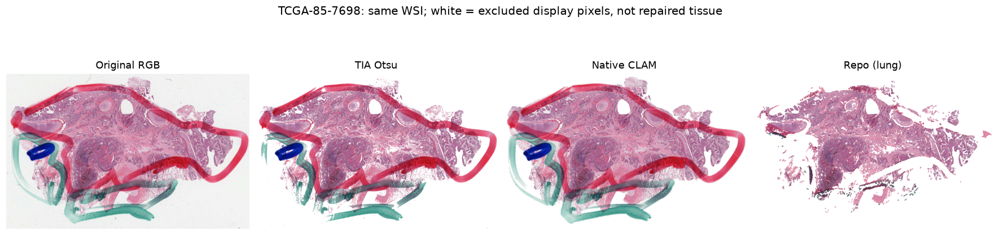

,method,selected_thumbnail_pixels_pct
0,TIA Otsu,45.73
1,Native CLAM,58.05
2,Repo (lung),29.11


Native CLAM segmentation: (2937, 1875) at level 3


In [7]:
from src.imaging_utils.masking import create_tissue_mask


def artifact_compare_slide(project, output, masking, artifacts):
    file_id = '5048c79f-ed1d-4534-8da2-1a4d207b2371'
    manifest_file = project / 'manifests/tcga_demo.csv'
    rows = pd.read_csv(manifest_file)
    rows = rows.loc[rows.file_id.eq(file_id)]
    assert len(rows) == 1, 'Expected one severe-artefact source record'
    record = rows.iloc[0].to_dict()
    assert record['case_submitter_id'] == 'TCGA-85-7698'
    path = (project / record['path']).resolve(strict=True)
    before = path.stat()
    image, info = read_thumbnail(path, 1024, 16_000_000, 16_000_000)
    h, w = image.shape[:2]
    tia_mask = create_tissue_mask(image, method='tia_otsu')
    combined = preprocess_masks(image, masking=deepcopy(masking), artifacts=deepcopy(artifacts))
    params = {'sthresh': 8, 'sthresh_up': 255, 'mthresh': 7, 'close': 4,
              'use_otsu': False, 'ref_patch_size': 512,
              'filter_params': {'a_t': 100, 'a_h': 16, 'max_n_holes': 8}}
    native = open_clam_slide(path)
    try:
        level = native.wsi.get_best_level_for_downsample(64)
        level_dimensions = tuple(map(int, native.level_dim[level]))
        assert np.prod(level_dimensions) <= 16_000_000, 'Native CLAM segmentation exceeds the read budget'
        native.segmentTissue(seg_level=level, **deepcopy(params))
        native_mask = contour_tile_mask(native.contours_tissue, native.holes_tissue,
                                       (0, 0), native.wsi.dimensions, (w, h))
        native_info = {'seg_level': level, 'seg_dimensions': level_dimensions,
                       'level0_pixels_per_seg_pixel_xy': list(native.level_downsamples[level]),
                       'contours': len(native.contours_tissue),
                       'holes': sum(map(len, native.holes_tissue)), 'parameters': params}
    finally:
        native.wsi.close()
    after = path.stat()
    assert (before.st_size, before.st_mtime_ns) == (after.st_size, after.st_mtime_ns), 'Source changed during comparison'
    masks = {'TIA Otsu': tia_mask, 'Native CLAM': native_mask, f'Repo ({PROFILE})': combined['clean']}
    folder = output / 'severe_artifact_comparison'
    folder.mkdir(exist_ok=True)
    save_png(folder / 'thumbnail.png', image)
    for name, selected in masks.items():
        assert selected.dtype == bool and selected.shape == image.shape[:2]
        save_png(folder / (name.lower().replace(' ', '_').replace('(', '').replace(')', '') + '_mask.png'), selected)
    evidence = {'source_path': str(path), 'source_file_id': file_id,
        'case_id': record['case_submitter_id'], 'source_manifest': str(manifest_file),
        'source_manifest_sha256': hashlib.sha256(manifest_file.read_bytes()).hexdigest(),
        'source_md5_declared': record['md5sum'], 'source_checksum_verified': False,
        'source_size_bytes': before.st_size, 'source_mtime_ns': before.st_mtime_ns,
        'source_stat_unchanged': True, 'thumbnail': info,
        'thumbnail_sha256': hashlib.sha256((folder / 'thumbnail.png').read_bytes()).hexdigest(),
        'read_budget_pixels_per_read_and_slide': 16_000_000,
        'tia': {'method': 'tia_otsu', 'artifact_cleanup': False},
        'native_clam': {'commit': CLAM_COMMIT, 'requested_downsample': 64, **native_info},
        'repo': {'profile': PROFILE, 'config_path': str(CONFIG_PATH), 'masking': deepcopy(masking), 'artifacts': deepcopy(artifacts),
                 'applied': combined['metadata']},
        'selected_percent': {name: float(selected.mean() * 100) for name, selected in masks.items()},
        'versions': {name: version(name) for name in
                     ['tiatoolbox', 'openslide-python', 'numpy', 'Pillow', 'opencv-python']},
        'source_sha256': {name: hashlib.sha256((project / name).read_bytes()).hexdigest()
            for name in ['src/wsi_preprocessing/inspection.py', 'src/imaging_utils/masking.py', 'src/wsi_preprocessing/pipeline.py', 'src/imaging_utils/filters.py',
                         'src/imaging_utils/quality.py', 'src/imaging_utils/arrays.py', 'src/wsi_preprocessing/tiling.py',
                         'third_party/CLAM/wsi_core/WholeSlideImage.py']},
        'scope': 'One severe-artefact WSI; CLAM segmentation scale differs; no accuracy reference; white exclusion is display only'}
    return image, masks, folder, evidence


artifact_rgb, artifact_masks, artifact_dir, artifact_provenance = artifact_compare_slide(
    PROJECT, OUT, MASKING, ARTIFACTS)
artifact_views = {'Original RGB': artifact_rgb,
                  **{name: np.where(selected[..., None], artifact_rgb, 255).astype(np.uint8)
                     for name, selected in artifact_masks.items()}}
artifact_fig, artifact_axes = plt.subplots(1, 4, figsize=(16, 4.5), layout='constrained')
for artifact_ax, (artifact_name, artifact_image) in zip(artifact_axes, artifact_views.items(), strict=True):
    artifact_ax.imshow(artifact_image)
    artifact_ax.set_title(artifact_name)
    artifact_ax.axis('off')
artifact_fig.suptitle('TCGA-85-7698: same WSI; white = excluded display pixels, not repaired tissue')
artifact_fig.savefig(artifact_dir / 'whole_slide_comparison.png')
plt.show()
display(pd.DataFrame({'method': list(artifact_masks),
                      'selected_thumbnail_pixels_pct': list(artifact_provenance['selected_percent'].values())}).round(2))
print('Native CLAM segmentation:', artifact_provenance['native_clam']['seg_dimensions'],
      'at level', artifact_provenance['native_clam']['seg_level'])


#### Inspect coloured strokes and the tissue they obscure
The crops below are fixed relative locations on the same slide, not three independent specimens. With the selected lung profile, inspect whether the visual comparison shows substantial coloured pen retained by raw TIA and native CLAM, and how much the combined colour exclusions remove from those strokes. **Residual dark ink can remain, and exclusion also discards the tissue pixels beneath a mark; it cannot reconstruct hidden tissue.** Inspect the new results after changing any settings rather than assuming this observation still holds.

White areas mean pixels excluded for this display; source RGB is unchanged. A smaller selected area is not automatically better. Choose the recipe and parameters for the **stain, tissue morphology and downstream task**, then review representative successes and failures with suitable reference annotations. H&E colour rules can remove legitimate special-stain colours, and aggressive cleanup can discard diagnostically relevant structures.


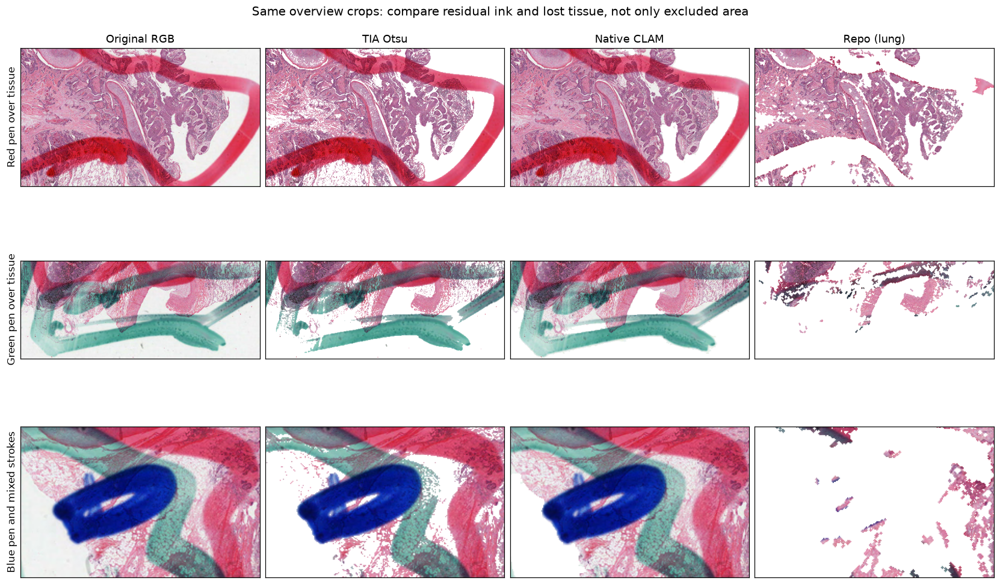

Saved comparison figures, masks and provenance in /Users/irina/Projects/digital-pathology-demo/outputs/pipeline-audit-20261103/normalisation-patch-mask-publish-validation/attempt-2/runs/20261103T212800Z_db611c8e/severe_artifact_comparison


In [8]:
# Coordinates refer to the audited 1024 × 654 overview and scale with the current canvas.
artifact_roi_reference = {'Red pen over tissue': (570, 185, 1010, 440),
                          'Green pen over tissue': (225, 445, 690, 635),
                          'Blue pen and mixed strokes': (55, 255, 285, 400)}
artifact_h, artifact_w = artifact_rgb.shape[:2]
artifact_rois = {}
artifact_fig, artifact_axes = plt.subplots(3, 4, figsize=(15, 9), layout='constrained')
for artifact_row, (artifact_label, artifact_box) in enumerate(artifact_roi_reference.items()):
    artifact_fraction = np.asarray(artifact_box, dtype=float) / [1024, 654, 1024, 654]
    artifact_x0, artifact_y0, artifact_x1, artifact_y1 = np.rint(
        artifact_fraction * [artifact_w, artifact_h, artifact_w, artifact_h]).astype(int)
    assert 0 <= artifact_x0 < artifact_x1 <= artifact_w and 0 <= artifact_y0 < artifact_y1 <= artifact_h
    artifact_rois[artifact_label] = {'fraction_xyxy': artifact_fraction.tolist(),
        'thumbnail_xyxy': [int(v) for v in (artifact_x0, artifact_y0, artifact_x1, artifact_y1)]}
    for artifact_col, (artifact_name, artifact_image) in enumerate(artifact_views.items()):
        artifact_ax = artifact_axes[artifact_row, artifact_col]
        artifact_ax.imshow(artifact_image[artifact_y0:artifact_y1, artifact_x0:artifact_x1])
        artifact_ax.set_title(artifact_name if artifact_row == 0 else '')
        artifact_ax.set_xticks([])
        artifact_ax.set_yticks([])
        if artifact_col == 0:
            artifact_ax.set_ylabel(artifact_label)
artifact_fig.suptitle('Same overview crops: compare residual ink and lost tissue, not only excluded area')
artifact_fig.savefig(artifact_dir / 'pen_detail_comparison.png')
plt.show()
artifact_provenance['display_rois'] = artifact_rois
(artifact_dir / 'provenance.json').write_text(json.dumps(artifact_provenance, indent=2))
print(f'Saved comparison figures, masks and provenance in {artifact_dir}')


### 3. Export the full eligible grid with upstream CLAM
The final binary mask is converted into tissue contours and child-hole contours in level-0 coordinates. The shared exporter calls pinned **CLAM `WholeSlideImage.process_contour`**, with padding disabled. The default `four_pt` rule accepts a tile if at least one of four interior points lies in a tissue contour; the lung profile sets `exclude_hole_centers=False`, so a centre inside a hole is not itself a veto. **Hole pixels remain unretained in the mask and in coverage calculations**, and blue hole contours remain visible. Each contour anchors its own grid. Smoothing can change contour bounds and therefore shift tile origins; changes in exact coordinates do not directly measure tissue-area gain or loss.

We export **every coordinate passing those contour rules and the configured retained-mask coverage threshold**: by default 256 output pixels at target 0.5 µm/pixel and at least 10% thumbnail-mask coverage. This is the complete eligible grid under those choices, not a claim that all anatomical tissue is covered or that selected regions are artefact-free. Up to 90% of the thumbnail-mask area within an eligible footprint can be unretained; this does not bound full-resolution tissue or artefact content; review this permissive threshold for the research question. A grid/contour safety budget raises an error instead of silently capping coordinates.

The canonical CLAM HDF5, a full coordinate CSV, and a thumbnail stitch show the entire export. The stitch uses existing thumbnail pixels inside all exported footprints; it is not a mosaic of newly decoded full-resolution patches. Only a **separate sample of up to 12 patches** is read later for visual QC and optional stain comparisons. Sampled QC never removes coordinates from the full export.

Source reads use CLAM's OpenSlide handle. Coordinate workers are bounded by upstream CLAM, while the small set of pixel reads remains sequential. Locations use level-0 `(x, y)` while arrays index `[y, x]`.

Upstream CLAM revision: 53e2409d4a8189c682c173382964a85f114f923c
1,111 eligible coordinates exported; no coordinate cap; no patch-image copies from the exporter.
Source region: 508 × 508 px → 256 × 256 px
Actual output MPP: 0.50006 × 0.50006


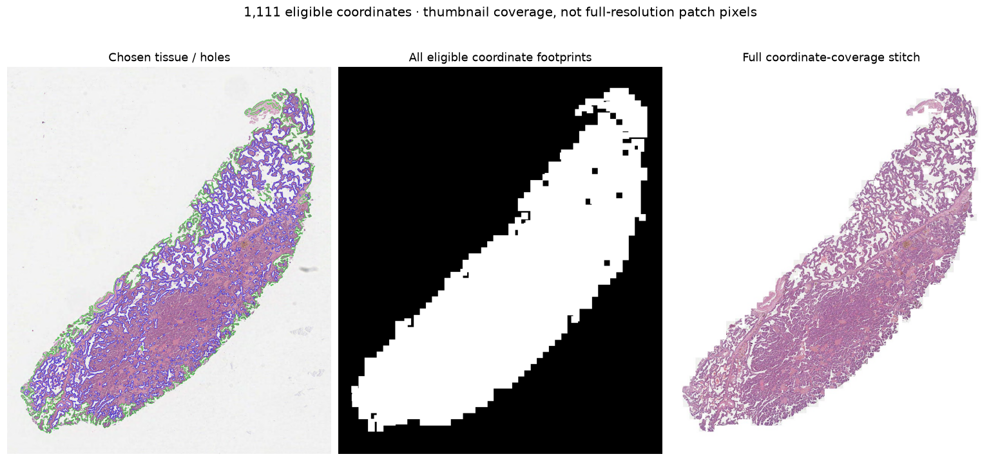

In [9]:
(read_w, read_h), (actual_mpp_x, actual_mpp_y) = calibrated_patch_size(
    TILE_PIXELS, TARGET_MPP, (mpp_x, mpp_y))
assert read_w * read_h <= MAX_TILE_READ_PIXELS
assert read_w == read_h, 'CLAM requires square source patches.'
segmentation_preview, _ = tissue_hole_preview(rgb, mask)
export_row = {**source, 'path': str(SLIDE_PATH)}
exports = export_slide(OUT, export_row, inspection, rgb, mask, segmentation_preview,
                       EXPORT, MASKING['method'])
assert exports['status'] == 'complete' and len(exports['layouts']) == 1
layout = exports['layouts'][0]
coords_path = OUT / layout['coords']
with h5py.File(coords_path, 'r') as handle:
    full_coords = handle['coords'][:]
    full_fractions = handle['tissue_fraction'][:]
    assert len(full_coords) == handle.attrs['eligible_count'] > 0
    assert handle.attrs['coordinate_limit'] == -1 and not handle.attrs['use_padding']
    assert handle.attrs['pixel_preview_count'] == 0
    assert bool(handle.attrs['exclude_hole_centers']) == bool(EXPORT.exclude_hole_centers)
    assert layout['exclude_hole_centers'] == bool(EXPORT.exclude_hole_centers)
    assert handle['coords'].attrs['patch_size'] == read_w
    assert handle['coords'].attrs['output_patch_size'] == TILE_PIXELS
    assert handle['coords'].attrs['target_mpp'] == TARGET_MPP
    assert np.allclose(handle['coords'].attrs['effective_mpp'], [actual_mpp_x, actual_mpp_y])
grid = pd.DataFrame(full_coords, columns=['x_level0', 'y_level0'])
grid.insert(0, 'coordinate_index', np.arange(len(grid)))
grid['thumbnail_tissue_fraction'] = full_fractions
full_table = grid.assign(slide_id=SLIDE_ID, read_level=0,
    read_width_level0=read_w, read_height_level0=read_h,
    output_width_px=TILE_PIXELS, output_height_px=TILE_PIXELS,
    output_mpp_x=actual_mpp_x, output_mpp_y=actual_mpp_y)
full_table.to_csv(OUT / 'eligible_coordinates.csv', index=False)
coverage_path = OUT / layout['coverage_mask']
stitch_path = OUT / layout['folder'] / 'stitches' / f'{SLIDE_ID}.jpg'
with Image.open(coverage_path) as image:
    coverage_mask = np.asarray(image).astype(bool)
with Image.open(stitch_path) as image:
    coverage_stitch = np.asarray(image.convert('RGB'))
assert coverage_mask.shape == mask.shape and coverage_stitch.shape == rgb.shape
print('Upstream CLAM revision:', CLAM_COMMIT)
print(f'{len(grid):,} eligible coordinates exported; no coordinate cap; no patch-image copies from the exporter.')
print(f'Source region: {read_w} × {read_h} px → {TILE_PIXELS} × {TILE_PIXELS} px')
print(f'Actual output MPP: {actual_mpp_x:.5f} × {actual_mpp_y:.5f}')

fig, axes = plt.subplots(1, 3, figsize=(14, 7), layout='constrained')
for ax, view, title in zip(axes, [segmentation_preview, coverage_mask, coverage_stitch],
        ['Chosen tissue / holes', 'All eligible coordinate footprints', 'Full coordinate-coverage stitch'], strict=True):
    ax.imshow(view, cmap='gray' if view.ndim == 2 else None)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle(f'{len(grid):,} eligible coordinates · thumbnail coverage, not full-resolution patch pixels')
fig.savefig(OUT / '03_full_coordinate_coverage.png')
plt.show()

def evenly_spaced(frame, n):
    if frame.empty or n == 0:
        return frame.iloc[:0]
    return frame.iloc[np.linspace(0, len(frame) - 1, min(n, len(frame)), dtype=int)]

selected = evenly_spaced(grid, N_QC_PATCHES).copy()
selected['sample_group'] = 'eligible-coordinate visual sample'
selected.insert(0, 'tile_id', [f'tile_{i:02d}' for i in range(len(selected))])


### 4. Read tiles and measure quality
We report two different quantities: **retained footprint coverage** from the combined thumbnail mask, and **coloured-pixel fraction** measured directly on each tile with the fitted CLAM saturation threshold. They differ because masking, closing, hole cleanup and downsampling alter the thumbnail representation.

For the sampled patches, a QC label passes only if **both fractions** meet `MIN_TISSUE_FRACTION`. Every exported coordinate already passed the thumbnail-coverage rule; these few raw-pixel measurements do not filter or relabel the full grid. This is still not complete artefact QC: a rectangular tile can contain some excluded pixels even when it passes.

**Laplacian variance** is an edge/detail score for visual review, not a calibrated blur detector. It varies with tissue, scale and contrast. “Keep” means passes these coverage rules, not approved for analysis.


In [10]:
tiles = {}
qc_rows = []
tile_started = time.monotonic()
reader = open_clam_slide(SLIDE_PATH)
try:
    for row in selected.itertuples():
        if time.monotonic() - tile_started > MAX_TILE_SECONDS:
            raise TimeoutError('Tile-reading budget exceeded; reduce the sample count.')
        tile_rgb = read_tile(reader, (row.x_level0, row.y_level0), (read_w, read_h),
                             TILE_PIXELS, max_read_pixels=MAX_TILE_READ_PIXELS)
        tile = Image.fromarray(tile_rgb)
        measures = tile_quality(tile_rgb, saturation_threshold=otsu_threshold)
        tissue_fraction = measures['tissue_fraction']
        detail_score = measures['laplacian_variance']
        passes = (row.thumbnail_tissue_fraction >= MIN_TISSUE_FRACTION
                  and tissue_fraction >= MIN_TISSUE_FRACTION)
        tiles[row.tile_id] = tile
        qc_rows.append({'tile_id': row.tile_id, 'tissue_fraction': tissue_fraction,
                        'laplacian_variance': detail_score,
                        'decision': 'keep' if passes else 'exclude',
                        'reason': 'coverage_pass_only' if passes
                                  else 'low_tissue_coverage'})
finally:
    handle = getattr(reader, 'wsi', None)
    if handle is not None:
        handle.close()
qc = selected.merge(pd.DataFrame(qc_rows), on='tile_id', validate='one_to_one')
display(qc[['tile_id', 'sample_group', 'tissue_fraction', 'laplacian_variance', 'decision']]
        .head(8).round(3))
print(qc.decision.value_counts().to_string())

,tile_id,sample_group,tissue_fraction,laplacian_variance,decision
0,tile_00,eligible-coordinate visual sample,0.590,1237.861,keep
1,tile_01,eligible-coordinate visual sample,0.712,1869.847,keep
2,tile_02,eligible-coordinate visual sample,0.654,1812.637,keep
3,tile_03,eligible-coordinate visual sample,0.863,2914.758,keep
4,tile_04,eligible-coordinate visual sample,0.723,2164.560,keep
5,tile_05,eligible-coordinate visual sample,0.465,1462.561,keep
6,tile_06,eligible-coordinate visual sample,0.808,2548.889,keep
7,tile_07,eligible-coordinate visual sample,0.533,1004.911,keep


decision
keep    12


### 5. Review sampled QC on the WSI thumbnail
One row shows the **original thumbnail**, **final green tissue/blue hole contours**, and **sampled QC locations**. Blue rectangles mark sampled coverage passes; orange rectangles mark sampled failures. Tile IDs link the overview to `sampled_tile_qc.csv` and the saved patches. No close-up patch-mask grid is displayed.

The thumbnail is coarse: it cannot establish focus quality, reliably identify small artefacts, or approve individual nuclei. The sampled decisions remain separate from the full eligible coordinate grid. All 12 bounded patch reads are retained for optional stain comparisons and separate inspection; their pass/fail labels never filter the complete coordinate export.

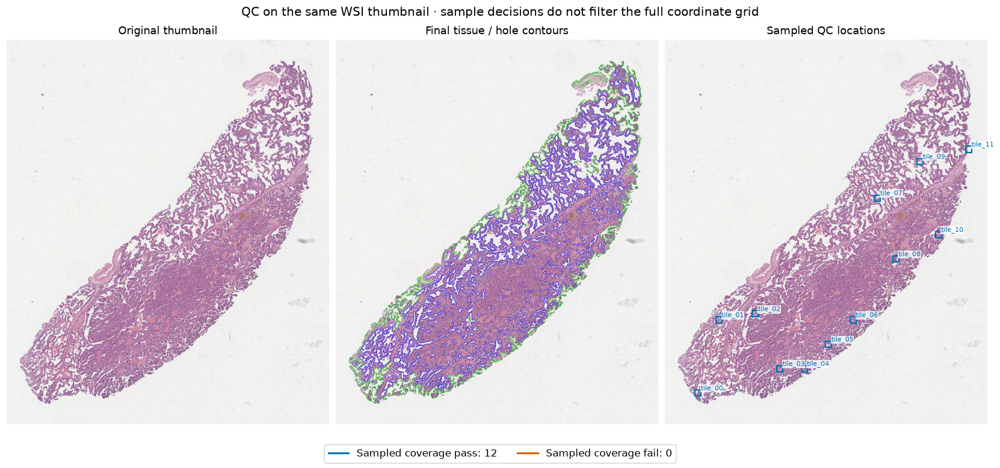

Lowest-detail sampled tiles for separate inspection: tile_11, tile_07, tile_09


In [11]:
from matplotlib.lines import Line2D

qc_contours_preview, _ = tissue_hole_preview(rgb, mask)
fig, axes = plt.subplots(1, 3, figsize=(15, 7), layout='constrained')
for ax, image, title in zip(axes, (rgb, qc_contours_preview, rgb),
        ('Original thumbnail', 'Final tissue / hole contours', 'Sampled QC locations'), strict=True):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')
qc_colours = {'keep': '#0072B2', 'exclude': '#D55E00'}
for row in qc.itertuples():
    x, y = row.x_level0 / scale_x, row.y_level0 / scale_y
    w, h = read_w / scale_x, read_h / scale_y
    colour = qc_colours[row.decision]
    axes[2].add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=colour, linewidth=1.5))
    axes[2].annotate(row.tile_id, (x + w / 2, y + h / 2), xytext=(3, 3),
        textcoords='offset points', color=colour, fontsize=7,
        bbox={'facecolor': 'white', 'alpha': .8, 'edgecolor': 'none', 'pad': .5})
legend = [Line2D([], [], color=qc_colours[decision], linewidth=2,
                    label=f"{label}: {int(qc.decision.eq(decision).sum())}")
          for decision, label in (('keep', 'Sampled coverage pass'), ('exclude', 'Sampled coverage fail'))]
fig.legend(handles=legend, loc='outside lower center', ncol=2)
fig.suptitle('QC on the same WSI thumbnail · sample decisions do not filter the full coordinate grid')
fig.savefig(OUT / '04_thumbnail_qc.png')
plt.show()

kept = qc[qc.decision.eq('keep')].sort_values('laplacian_variance')
if not kept.empty:
    print('Lowest-detail sampled tiles for separate inspection:', ', '.join(kept.head(3).tile_id))

### TIA stain normalisation
Four methods transform the same three sampled patches using one reference, chosen as the QC-passing tile with the highest coloured-pixel fraction. This is a deterministic demonstration reference, not a scientifically validated one. In predictive studies, choose the reference from training data only.

| Method | Main idea | What to inspect |
| --- | --- | --- |
| Reinhard | Match LAB colour moments | Tissue/background proportion |
| Macenko | Estimate optical-density stain directions | Colours and concentration scaling |
| Ruifrok–Johnston | Use a fixed H&E stain matrix | Suitability for stain/scanner |
| Vahadane | Learn stain directions | Stability and unusual colour changes |

TIA 2.1.3 warns that Vahadane is unstable with newer scikit-learn dictionary learning. We retain that warning and fix the NumPy seed; successful execution does not establish scientific reliability.

Two grids compare all methods, with **one patch per row and methods in columns**:

- **Original background:** unmasked reference/source RGB, with no background restoration.
- **Shared mean background:** replace pixels outside the patch-resolution tissue masks with the same estimated slide-background RGB before normalisation, then restore that value afterwards. The estimate uses thumbnail pixels outside the final mask, excluding CODAIT candidates.

**Resolve normalization masks at patch resolution.** Projecting coarse thumbnail contours can create large angular cutouts. For these four already-read patches only, we apply CODAIT exclusions and the same slide-fitted grayscale/saturation thresholds to the actual 256-pixel RGB. We fix median=1, closing=0, hole filling=0 and minimum component area=0, so thumbnail-scale size rules are not reused on patch pixels. This does not change the slide mask or CLAM coordinate export.

`NORMALISATION_MASK_KERNEL_SIZE=3` rounds the new **binary** masks with elliptical opening then closing, in output-patch pixels. Boolean edge replication before morphology avoids imposing an artificial blank frame; it does not supply missing tissue context. We crop back and reapply local artefact exclusions. Source RGB is neither padded, blurred nor inpainted. Both the reference and source masks use this policy, recorded with thresholds, per-patch changes and RGB hashes.

The reference and input-preparation figures show what enters these two paths. All normalised patch PNGs and provenance are saved separately from the unchanged raw patches.

The fixed thresholds and colour exclusions can still remove pale tissue or retain artefacts; opening can erase narrow structures and closing can change spaces. The background estimate can include misclassified tissue or missed artefacts. This refinement is not validated anatomical segmentation. **Constant-background filling is not masked-statistics normalisation:** TIA still includes background in colour moments or concentration percentiles, so tissue proportion affects results. A multi-slide study needs a reviewed, shared background convention and reference.

These same-slide comparisons illustrate colour changes, not correction of between-site variation or improved prediction. Inspect clipping, lost detail and unusual hues alongside any downstream validation.


Normalisation mask smoothing: ['opening', 'closing'] kernel = 3 output-patch pixels
Mean background RGB: [239.   237.67 238.19] → fill RGB: [239 238 238]


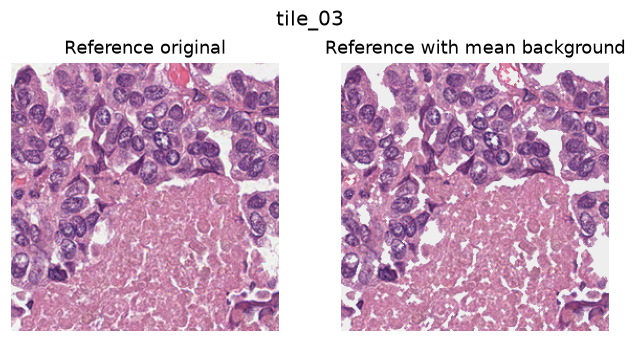

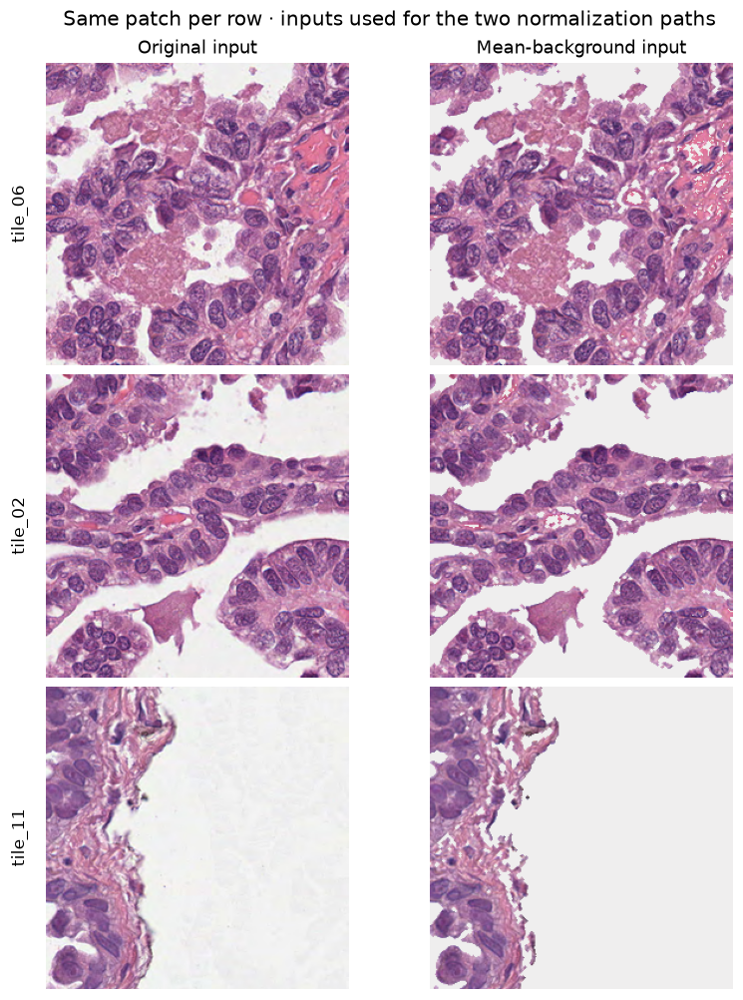

|2026-11-03|21:28:28.175| [WARNING] Vahadane stain extraction/normalization algorithms are unstable after the update to `dictionary learning` algorithm in scikit-learn > v0.23.0 (see issue #382). Please be advised and consider using other stain extraction (normalization) algorithms.


|2026-11-03|21:28:28.226| [WARNING] Vahadane stain extraction/normalization algorithms are unstable after the update to `dictionary learning` algorithm in scikit-learn > v0.23.0 (see issue #382). Please be advised and consider using other stain extraction (normalization) algorithms.


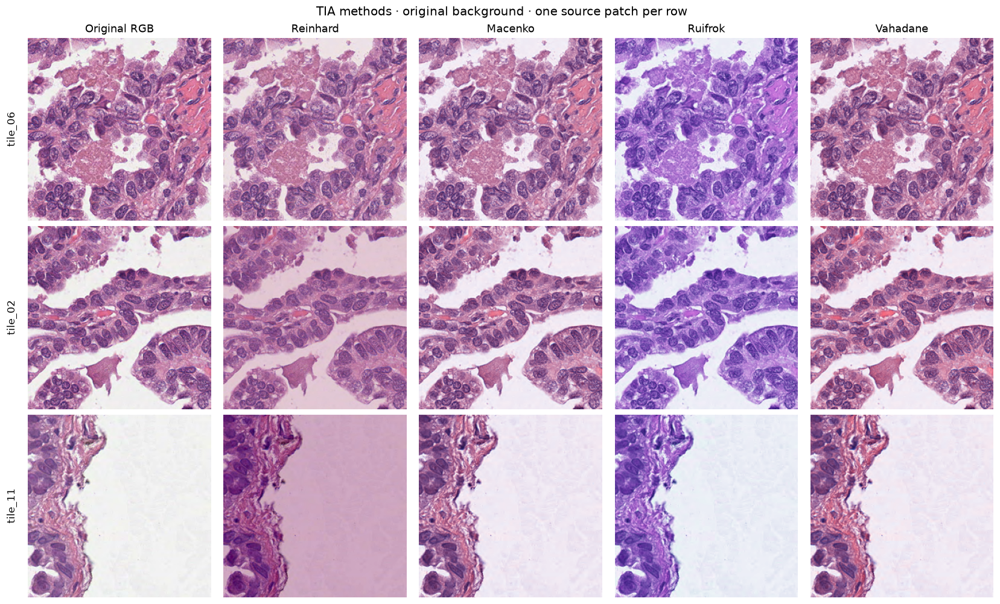

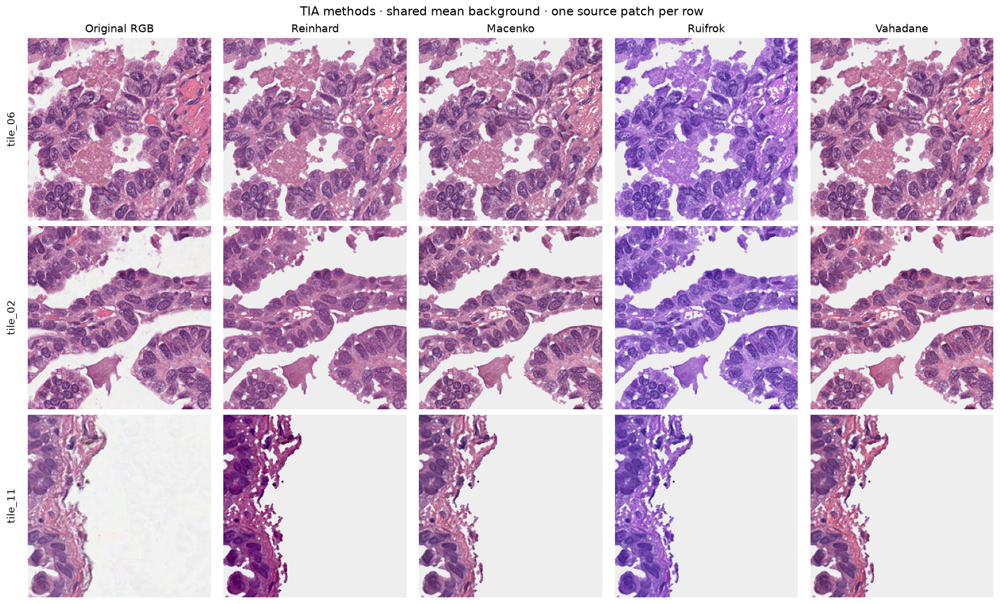

,method,seconds
0,reinhard,0.05
1,macenko,0.06
2,ruifrok,0.03
3,vahadane,0.10


4740

In [12]:
STAIN_METHODS = ['reinhard', 'macenko', 'ruifrok', 'vahadane']
STAIN_SEED = 0  # The reusable comparison resets each call and restores caller RNG state.
retained = qc[qc.decision.eq('keep')].sort_values('tissue_fraction', ascending=False)
assert len(retained) >= 4, 'Need at least four retained tiles for this comparison; review QC first.'
REFERENCE_TILE_ID = retained.iloc[0].tile_id  # Edit to another retained tile ID if desired.
assert REFERENCE_TILE_ID in set(retained.tile_id)
source_ids = evenly_spaced(retained[retained.tile_id.ne(REFERENCE_TILE_ID)], 3).tile_id.tolist()
# Resolve boundaries on the actual patches; do not magnify coarse thumbnail contours.
from src.imaging_utils.arrays import smooth_mask_edges

NORMALISATION_MASK_KERNEL_SIZE = 3  # Output-patch pixels, independent of thumbnail smoothing.
normalisation_patch_masking = {**MASKING,
    'tia_threshold': result['metadata']['tia_threshold'],
    'use_otsu': False, 'saturation_threshold': result['metadata']['clam_saturation_threshold'],
    'median_size': 1, 'closing_size': 0, 'max_hole_area': 0, 'smoothing_kernel_size': 0}
normalisation_patch_artifacts = {**ARTIFACTS, 'min_tissue_area': 0}
normalisation_padding = max(1, 2 * (NORMALISATION_MASK_KERNEL_SIZE - 1))
normalisation_masks, normalisation_mask_details = {}, {}
for tile_id in [REFERENCE_TILE_ID, *source_ids]:
    patch_rgb = np.asarray(tiles[tile_id])
    patch_rgb_hash = hashlib.sha256(patch_rgb.tobytes()).hexdigest()
    patch_result = preprocess_masks(patch_rgb, masking=normalisation_patch_masking,
                                    artifacts=normalisation_patch_artifacts)
    patch_before = patch_result['clean']
    # Replicate BOOLEAN edge values so morphology does not invent a blank frame.
    padded_mask = np.pad(patch_before, normalisation_padding, mode='edge')
    smoothed_patch = smooth_mask_edges(padded_mask, NORMALISATION_MASK_KERNEL_SIZE)[
        normalisation_padding:normalisation_padding + TILE_PIXELS,
        normalisation_padding:normalisation_padding + TILE_PIXELS]
    patch_mask = smoothed_patch & ~patch_result['excluded']
    assert patch_mask.dtype == bool and patch_mask.shape == patch_rgb.shape[:2]
    assert not np.any(patch_mask & patch_result['excluded'])
    assert hashlib.sha256(patch_rgb.tobytes()).hexdigest() == patch_rgb_hash
    normalisation_masks[tile_id] = patch_mask
    normalisation_mask_details[tile_id] = {
        'source_rgb_sha256': patch_rgb_hash,
        'mask_sha256': hashlib.sha256(patch_mask.tobytes()).hexdigest(),
        'smoothing_added_pixels': int((smoothed_patch & ~patch_before).sum()),
        'smoothing_removed_pixels': int((patch_before & ~smoothed_patch).sum()),
        'artifact_excluded_pixels': int(patch_result['excluded'].sum()),
        'post_smoothing_excluded_pixels': int((smoothed_patch & patch_result['excluded']).sum()),
        'retained_pixels': int(patch_mask.sum()), 'source_rgb_unchanged': True}
normalisation_smoothing = {
    'source': 'actual output-patch RGB with fixed slide-fitted thresholds',
    'kernel_size_output_patch_pixels': NORMALISATION_MASK_KERNEL_SIZE,
    'operations': ['opening', 'closing'] if NORMALISATION_MASK_KERNEL_SIZE >= 3 else [],
    'border_policy': 'replicate binary-mask edges, smooth, crop to original extent',
    'binary_padding_pixels': normalisation_padding,
    'masking': normalisation_patch_masking, 'artifacts': normalisation_patch_artifacts,
    'slide_thresholds_frozen': True, 'thumbnail_contours_projected': False,
    'rgb_blurring_or_inpainting': False, 'patches': normalisation_mask_details}
print('Normalisation mask smoothing:', normalisation_smoothing['operations'],
      'kernel =', NORMALISATION_MASK_KERNEL_SIZE, 'output-patch pixels')
reference_rgb = np.asarray(tiles[REFERENCE_TILE_ID])
reference_mask = normalisation_masks[REFERENCE_TILE_ID]
# A single slide-level estimate is shared by the reference and every source tile.
background_sample_mask = ~mask & ~result['stages']['codait_excluded']
background_mean_rgb = mean_background_color(rgb, background_sample_mask)
BACKGROUND_RGB = np.rint(background_mean_rgb).astype(np.uint8)
print('Mean background RGB:', background_mean_rgb.round(2), '→ fill RGB:', BACKGROUND_RGB)
reference_prepared = prepare_stain_image(reference_rgb, tissue_mask=reference_mask,
                                        background_rgb=BACKGROUND_RGB)
stain_dir = OUT / 'stain_normalisation'
stain_dir.mkdir(exist_ok=True)
save_png(stain_dir / 'background_sample_mask.png', background_sample_mask)
save_png(stain_dir / 'reference_original.png', reference_rgb)
save_png(stain_dir / 'reference.png', reference_prepared)
save_png(stain_dir / 'reference_tissue_mask.png', reference_mask)
fig, axes = plt.subplots(1, 2, figsize=(6, 3), layout='constrained')
for ax, image, title in zip(axes, [reference_rgb, reference_prepared],
                            ['Reference original', 'Reference with mean background']):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle(REFERENCE_TILE_ID)
fig.savefig(OUT / '05a_stain_reference.png')
plt.show()

# Keep one source patch per row and the two input conventions in columns.
fig, axes = plt.subplots(len(source_ids), 2, figsize=(7, 3 * len(source_ids)),
                         squeeze=False, layout='constrained')
for row_index, tile_id in enumerate(source_ids):
    original = np.asarray(tiles[tile_id])
    tissue = normalisation_masks[tile_id]
    prepared = prepare_stain_image(original, tissue_mask=tissue, background_rgb=BACKGROUND_RGB)
    assert np.array_equal(prepared[tissue], original[tissue])
    assert (prepared[~tissue] == BACKGROUND_RGB).all()
    save_png(stain_dir / f'{tile_id}_mean_background.png', prepared)
    save_png(stain_dir / f'{tile_id}_tissue_mask.png', tissue)
    for column, (image, title) in enumerate(zip(
            (original, prepared), ('Original input', 'Mean-background input'), strict=True)):
        axes[row_index, column].imshow(image)
        if row_index == 0:
            axes[row_index, column].set_title(title)
        axes[row_index, column].axis('off')
    axes[row_index, 0].text(-.06, .5, tile_id, transform=axes[row_index, 0].transAxes,
                           rotation=90, ha='right', va='center')
fig.suptitle('Same patch per row · inputs used for the two normalization paths')
fig.savefig(OUT / '05b_stain_inputs.png')
plt.show()

source_images = {tile_id: np.asarray(tiles[tile_id]) for tile_id in source_ids}
source_masks = {tile_id: normalisation_masks[tile_id] for tile_id in source_ids}
original_snapshots = {key: value.copy() for key, value in source_images.items()}
reference_snapshot = reference_rgb.copy()
rng_before = np.random.get_state()
comparison = compare_stain_normalization(reference_rgb, source_images,
    reference_mask=reference_mask, source_masks=source_masks, background_rgb=BACKGROUND_RGB,
    methods=STAIN_METHODS, random_seed=STAIN_SEED, max_pixels=MAX_TILE_READ_PIXELS)
rng_after = np.random.get_state()
assert rng_before[0] == rng_after[0] and np.array_equal(rng_before[1], rng_after[1])
assert rng_before[2:] == rng_after[2:], 'Comparison changed the caller NumPy RNG state'
assert np.array_equal(reference_rgb, reference_snapshot), 'Reference was modified'
# Save every computed patch result; display each output once in the method grids below.
for method, outputs in comparison['images'].items():
    for tile_id in source_ids:
        original = source_images[tile_id]
        tissue = source_masks[tile_id]
        assert np.array_equal(original, original_snapshots[tile_id]), 'Original was modified'
        for mode, images in outputs.items():
            transformed = images[tile_id]
            assert transformed.dtype == np.uint8 and transformed.shape == original.shape
            if mode == 'constant_background':
                assert (transformed[~tissue] == BACKGROUND_RGB).all()
            save_png(stain_dir / f'{tile_id}_{method}_{mode}.png', transformed)

# Compare methods directly, retaining the same patch identity along each row.
for mode, mode_label in (('unmasked', 'original background'),
                         ('constant_background', 'shared mean background')):
    fig, axes = plt.subplots(len(source_ids), len(STAIN_METHODS) + 1,
        figsize=(3 * (len(STAIN_METHODS) + 1), 3 * len(source_ids)),
        squeeze=False, layout='constrained')
    for row_index, tile_id in enumerate(source_ids):
        views = [('Original RGB', source_images[tile_id])]
        views += [(method.title(), comparison['images'][method][mode][tile_id])
                  for method in STAIN_METHODS]
        for column, (title, image) in enumerate(views):
            axes[row_index, column].imshow(image)
            if row_index == 0:
                axes[row_index, column].set_title(title)
            axes[row_index, column].axis('off')
        axes[row_index, 0].text(-.06, .5, tile_id, transform=axes[row_index, 0].transAxes,
                               rotation=90, ha='right', va='center')
    fig.suptitle(f'TIA methods · {mode_label} · one source patch per row')
    fig.savefig(OUT / f'05c_stain_methods_{mode}.png')
    plt.show()
display(pd.DataFrame(comparison['timings']).round(2))

stain_provenance = {'backend': 'TIAToolbox', 'version': version('tiatoolbox'),
    'methods': STAIN_METHODS, 'numpy_seed_per_call': STAIN_SEED,
    'timings': comparison['timings'],
    'vahadane_caveat': 'TIA warns of instability with newer scikit-learn dictionary learning',
    'reference_tile_id': REFERENCE_TILE_ID,
    'reference_slide_id': SLIDE_ID, 'source_tile_ids': source_ids,
    'background_modes': {'unmasked': 'original reference/source RGB; no masking or restoration',
        'constant_background': 'replace reference/source background with shared slide mean before TIA; restore after'},
    'background_rgb': BACKGROUND_RGB.tolist(),
    'background_mean_rgb_unrounded': background_mean_rgb.tolist(),
    'background_estimation': 'mean of original thumbnail pixels outside final mask, excluding CODAIT candidates',
    'background_sample_pixels': int(background_sample_mask.sum()),
    'mask_source': 'patch-resolution CODAIT/TIA/saturation masks with frozen slide thresholds and binary edge smoothing',
    'binary_mask_smoothing': normalisation_smoothing,
    'tissue_fractions': {key: float(value.mean()) for key, value in normalisation_masks.items()},
    'statistics_scope': 'TIA defaults in both paths; constant filling does not exclude background pixels from statistics',
    'reference_selection': 'highest coloured-pixel fraction among retained sampled tiles',
    'scope': 'same-slide visual demonstration only; raw exports unchanged'}
(stain_dir / 'provenance.json').write_text(json.dumps(stain_provenance, indent=2))


### 6. Save full coordinates and the separate visual-QC sample
The HDF5 and `eligible_coordinates.csv` contain the complete eligible grid; the coverage mask/stitch includes every exported footprint. `sampled_tile_qc.csv` and `qc_tiles/` contain only the small visual sample, including any failed coverage examples for review. Do not interpret those sampled decisions as QC approval for unsampled coordinates.

The source WSI stays in its canonical location; the CLAM layout links to it. Level-0 coordinates, source region dimensions and effective output MPP locate every tile. Split machine-learning datasets **by patient**, keeping slides and tiles from one patient together. Persist the chosen processing settings and justify them for the scientific task.

In [13]:
(OUT / 'qc_tiles').mkdir(exist_ok=True)
for tile_id, tile in tiles.items():
    tile.save(OUT / 'qc_tiles' / f'{tile_id}.png')
thumbnail.save(OUT / 'thumbnail.png')
for name, array in result['stages'].items():
    save_png(OUT / f'stage_{name}.png', array)
save_png(OUT / 'tissue_mask.png', mask)
qc['slide_id'] = SLIDE_ID
qc['case_id'] = source['case_submitter_id']
qc['read_level'] = 0
qc['read_width_level0'] = read_w
qc['read_height_level0'] = read_h
qc['output_width_px'] = qc['output_height_px'] = TILE_PIXELS
qc['output_mpp_x'] = actual_mpp_x
qc['output_mpp_y'] = actual_mpp_y
qc['tile_path'] = 'qc_tiles/' + qc.tile_id + '.png'
qc.to_csv(OUT / 'sampled_tile_qc.csv', index=False)

provenance = {
    'source_path': str(SLIDE_PATH), 'openslide_metadata': slide_metadata,
    'profile': PROFILE, 'config_path': str(CONFIG_PATH),
    'config_sha256': hashlib.sha256(CONFIG_PATH.read_bytes()).hexdigest(),
    'profile_comparison': {'generic_config_path': str(PROJECT / 'configs/preprocess.yaml'),
        'generic_masking': generic_masking, 'generic_artifacts': generic_artifacts,
        'measurements': profile_comparison, 'used_for_tiling': False},
    'binary_mask_smoothing': mask_smoothing_provenance,
    'original_thumbnail_rgb_sha256': rgb_before_preprocessing_sha256,
    'tiling_backend': 'CLAM', 'clam_commit': CLAM_COMMIT, 'clam_contour_fn': CLAM_CONTOUR_FN,
    'normalisation_demo': stain_provenance, 'source_manifest': str(manifest_path),
    'source_file_id': SLIDE_ID, 'source_original_filename': source['file_name'],
    'source_md5_verified': source_md5, 'source_size_bytes': SLIDE_PATH.stat().st_size,
    'source_url': f'https://portal.gdc.cancer.gov/files/{SLIDE_ID}',
    'case_id': source['case_submitter_id'], 'project': source['project'],
    'run_utc': run_id, 'level_dimensions': levels, 'level_downsamples': downsamples,
    'native_mpp_xy': [mpp_x, mpp_y], 'thumbnail_level': thumb_level,
    'thumbnail_dimensions': [thumb_w, thumb_h], 'thumbnail_scale_xy': [scale_x, scale_y],
    'parameters': {'target_mpp': TARGET_MPP, 'tile_pixels': TILE_PIXELS,
        'min_tissue_fraction': MIN_TISSUE_FRACTION, 'masking': MASKING, 'artifacts': ARTIFACTS,
        'thumbnail_edge': THUMBNAIL_EDGE, 'max_thumbnail_read_pixels': MAX_THUMBNAIL_READ_PIXELS,
        'n_visual_qc_patches': N_QC_PATCHES,
        'export': OmegaConf.to_container(EXPORT, resolve=True),
        'max_grid_positions': MAX_GRID_POSITIONS, 'max_contours': MAX_CONTOURS, 'max_tile_read_pixels': MAX_TILE_READ_PIXELS,
        'max_tile_seconds': MAX_TILE_SECONDS},
    'preprocessing': result['metadata'],
    'colour_handling': 'raw tile exports retain decoded scanner RGB; optional TIA comparisons are saved separately; no ICC conversion',
    'coordinate_export': exports,
    'coordinate_csv': 'eligible_coordinates.csv',
    'coordinate_h5_sha256': hashlib.sha256(coords_path.read_bytes()).hexdigest(),
    'sampling': 'few evenly spaced eligible coordinates for visual QC only; not representative',
    'sampled_qc_filters_full_grid': False,
    'qc_scope': 'thumbnail CODAIT/TIA/CLAM QC plus raw tile colour coverage; focus remains visual review',
    'eligible_coordinates_exported': len(grid), 'tiles_read_for_qc': len(qc),
    'decision_counts': {str(k): int(v) for k, v in qc.decision.value_counts().items()},
    'python': platform.python_version(),
    'source_module_sha256': source_hashes(PROJECT),
    'versions': {name: version(name) for name in
                 ['openslide-python', 'tiatoolbox', 'numpy', 'pandas', 'Pillow', 'opencv-python', 'matplotlib']},
}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2))
print(f'Saved all {len(grid):,} eligible coordinates and a separate {len(qc)}-patch visual-QC sample.')

Saved all 1,111 eligible coordinates and a separate 12-patch visual-QC sample.


## References and source
- [CLAM segmentation implementation](https://github.com/mahmoodlab/CLAM/blob/master/wsi_core/WholeSlideImage.py): saturation/median/threshold/closing and contour-based hole selection. Our bounded raster hole policy differs.
- [TIA OtsuTissueMasker](https://tia-toolbox.readthedocs.io/en/latest/_autosummary/tiatoolbox.tools.tissuemask.OtsuTissueMasker.html): grayscale thresholding.
- CODAIT filter attribution and original rule constants are retained in `src/imaging_utils/filters.py` and `third_party/`.

- [OpenSlide Python documentation](https://openslide.org/api/python/): pyramid levels, physical metadata and region coordinates.
- [histolab tissue-mask examples](https://histolab.readthedocs.io/en/latest/tissue_masks.html): mask overlays and multiple tissue fragments.
- [Wölflein et al., Benchmarking Pathology Feature Extractors](https://arxiv.org/abs/2311.11772): task-specific evidence concerning stain normalisation; findings do not establish a universal rule.
- [GDC source record](https://portal.gdc.cancer.gov/files/20c9afac-0d0c-4fcf-b3bf-a2beba3dd76b): local public TCGA-LUAD WSI, identified by the project manifest and verified checksum. The WSI is not bundled into the notebook.
- [TIA stain-normalisation API](https://tia-toolbox.readthedocs.io/en/latest/_autosummary/tiatoolbox.tools.stainnorm.html): actual Reinhard, Macenko, Ruifrok and Vahadane implementations used above.
